# Solar radiation comparison



## Set up

In [1]:
# paths of weight files

path_weight_CaSR='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-CaSR_202108.nc'
path_weight_HRDPS25='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-continental2.5-hrdps.nc'
path_weight_HRDPS1='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-1km_202108.nc'
path_weight_HRDPS10='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-subsampled_202108.nc'

# Grid Regions
REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}


In [10]:

from pathlib import Path
import calendar
from datetime import date
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

YEAR = 2023
MONTHS = 3,6,9,12
REGION_NAME = "SandHeads"

OUTPUT_DIR = '/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_solar/'
# When False, missing daily forcing files raise an error; True logs and skips them.
SKIP_MISSING_FILES = True

REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}

# Atmospheric *source* grid (y, x) shapes, daily file patterns and weights.
FORCINGS = {
    "CaSR": {
        "shape": (105, 70),
        "file_pattern": "/ocean/jqiu/forcings/CaSR/CaSR_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-CaSR_202108.nc",
    },
    "HRDPS25": {
        "shape": (230, 190),
        "file_pattern": "/results/forcing/atmospheric/continental2.5/nemo_forcing/hrdps_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-continental2.5-hrdps.nc",
    },
    "HRDPS1": {
        "shape": (1180, 1330),
        "file_pattern": "/ocean/jqiu/forcings/HRDPS_1km/HRDPS_1km_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-1km_202108.nc",
    },
    "HRDPS10": {
        "shape": (58, 48),
        "file_pattern": "/ocean/jqiu/forcings/HRDPS_subsampled/hrdps_subsampled_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-subsampled_202108.nc",
    },
}

j0, j1, i0, i1 = REGIONS[REGION_NAME]
assert 0 <= j0 < j1 and 0 <= i0 < i1
region_slices = {"y": slice(j0, j1), "x": slice(i0, i1)}
n_region_points = (j1 - j0) * (i1 - i0)

## Extract solar radiation


In [3]:
def load_region_weights(path, target_slices, forcing_shape):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing weights file: {path}")
    with xr.open_dataset(path) as ds:
        for k in range(1, 5):
            for prefix in ("src", "wgt"):
                var = f"{prefix}0{k}"
                if var not in ds:
                    raise KeyError(f"{var} is missing from {path}")
        # Ensure the entire region exists in the NEMO target grid.
        if ds.sizes["y"] < target_slices["y"].stop or ds.sizes["x"] < target_slices["x"].stop:
            raise ValueError(f"Region lies outside target grid in {path}")
        source = np.stack([
            ds[f"src0{k}"].isel(**target_slices).transpose("y", "x").values
            for k in range(1, 5)
        ]).reshape(4, -1)
        weights = np.stack([
            ds[f"wgt0{k}"].isel(**target_slices).transpose("y", "x").values
            for k in range(1, 5)
        ]).reshape(4, -1).astype(float)


    source = source.astype(np.int64) - 1
 
    n_source = np.prod(forcing_shape)
    invalid = (source < 0) | (source >= n_source)

    
    weights = np.where(invalid, 0.0, weights)
    source = np.where(invalid, 0, source)


    return source, weights

region_weights = {}
for forcing, config in FORCINGS.items():
    src, wgt = load_region_weights(config["weights"], region_slices, config["shape"])
    assert src.shape == (4, n_region_points)
    region_weights[forcing] = (src, wgt)
    print(f"{forcing}: {src.shape[1]} target ocean cells, weights loaded")


CaSR: 400 target ocean cells, weights loaded
HRDPS25: 400 target ocean cells, weights loaded
HRDPS1: 400 target ocean cells, weights loaded
HRDPS10: 400 target ocean cells, weights loaded


In [8]:
def timestamp_string(value):
    if isinstance(value, np.datetime64):
        return np.datetime_as_string(value, unit="s")
    if hasattr(value, "strftime"):
        return value.strftime("%Y-%m-%dT%H:%M:%S")
    raise ValueError(f"Unsupported timestamp: {value!r}")

def process_daily_file(path, source_shape, source_index, weights, expected_date):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)

    records = []

    with xr.open_dataset(path) as ds:
        var_name = "solar"

        if var_name not in ds:
            raise KeyError(f"{var_name} not found in {path}")

        var = ds[var_name]

        if not {"time_counter", "y", "x"}.issubset(var.dims):
            raise ValueError(f"Unexpected dims for {var_name}: {var.dims}")

        if (var.sizes["y"], var.sizes["x"]) != source_shape:
            raise ValueError(f"{var_name} grid shape mismatch in {path}")

        if "time_counter" not in ds.coords:
            raise ValueError(f"Missing time_counter coordinate: {path}")

        times = ds["time_counter"].values

        for t, time_value in enumerate(times):
            timestamp = timestamp_string(time_value)

            if timestamp[:10] != expected_date.isoformat():
                raise ValueError(f"Unexpected timestamp {timestamp} in {path}")

            # Extract solar radiation
            solar = (
                ds["solar"]
                .isel(time_counter=t)
                .transpose("y", "x")
                .values
                .ravel()
            )

            # Apply spatial interpolation weights
            solar_neighbors = solar[source_index]

            used = np.abs(weights) > 0

            valid = np.all(
                ~used | np.isfinite(solar_neighbors),
                axis=0
            )

            solar_grid = np.sum(
                np.where(used, solar_neighbors, 0.0) * weights,
                axis=0
            )

            solar_grid[~valid] = np.nan

            n_valid = int(np.isfinite(solar_grid).sum())

            records.append({
                "time": timestamp,
                "solar": float(np.nanmean(solar_grid)) if n_valid else np.nan,
                "n_valid": n_valid,
            })

    return records



In [11]:

# Extract
results = []
missing_files = []

for forcing, config in FORCINGS.items():
    src, wgt = region_weights[forcing]
    count = 0

    for month in MONTHS:
        n_days = calendar.monthrange(YEAR, month)[1]

        for day in range(1, n_days + 1):
            this_date = date(YEAR, month, day)

            daily_path = config["file_pattern"].format(
                year=YEAR,
                month=month,
                day=day
            )

            if not Path(daily_path).is_file():
                if not SKIP_MISSING_FILES:
                    raise FileNotFoundError(daily_path)

                missing_files.append(daily_path)
                continue

            daily_records = process_daily_file(
                daily_path,
                config["shape"],
                src,
                wgt,
                this_date
            )

            for record in daily_records:
                record.update({
                    "forcing": forcing,
                    "region": REGION_NAME,
                    "n_region_points": n_region_points
                })

            results.extend(daily_records)
            count += len(daily_records)

        print(f"{forcing}: {YEAR}-{month:02d} processed")

    print(f"{forcing}: {count} total time records processed")


if not results:
    raise RuntimeError(
        "No forcing records were processed. "
        "Check paths and selected year/months."
    )

df_long = (
    pd.DataFrame(results)
    .sort_values(["time", "forcing"])
    .reset_index(drop=True)
)

df_long["time"] = pd.to_datetime(df_long["time"])

df_wide = (
    df_long
    .pivot(index="time", columns="forcing", values="solar")
    .reset_index()
)

df_wide.columns.name = None

CaSR: 2023-03 processed
CaSR: 2023-06 processed
CaSR: 2023-09 processed
CaSR: 2023-12 processed
CaSR: 2928 total time records processed
HRDPS25: 2023-03 processed
HRDPS25: 2023-06 processed
HRDPS25: 2023-09 processed
HRDPS25: 2023-12 processed
HRDPS25: 2928 total time records processed
HRDPS1: 2023-03 processed
HRDPS1: 2023-06 processed
HRDPS1: 2023-09 processed
HRDPS1: 2023-12 processed
HRDPS1: 2856 total time records processed
HRDPS10: 2023-03 processed
HRDPS10: 2023-06 processed
HRDPS10: 2023-09 processed
HRDPS10: 2023-12 processed
HRDPS10: 2928 total time records processed


In [12]:
# save

save_path = OUTPUT_DIR + f"{REGION_NAME}_Solar.csv"

df_wide.to_csv(save_path, index=False)

print(f"Saved wide CSV: {save_path}")

Saved wide CSV: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_solar/SandHeads_Solar.csv


## Scatter Plot

In [13]:
# paths

path_csv='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_solar/SandHeads_Solar.csv'


DAILY MEAN SOLAR RADIATION STATISTICS
Reference: HRDPS2.5
Bias = Experiment - HRDPS2.5
Bias and RMSE units: W/m²

 Month Experiment     Bias    RMSE      R  p_value Significance  N_pairs
     3       CaSR  10.9859 22.8548 0.9394   0.0054           **       31
     3     HRDPS1  -4.7167 28.8320 0.8848   0.3965           ns       28
     3    HRDPS10  -0.6222  2.0426 0.9994   0.0900           ns       31
     6       CaSR -12.5528 43.6015 0.8589   0.1163           ns       30
     6     HRDPS1  -4.5584 22.0113 0.9673   0.2636           ns       30
     6    HRDPS10  -0.0862  1.2528 0.9999   0.7130           ns       30
     9       CaSR  -3.5000 22.8396 0.9468   0.4105           ns       30
     9     HRDPS1  -2.6874 14.0198 0.9774   0.3016           ns       30
     9    HRDPS10   0.1142  0.9875 0.9999   0.5356           ns       30
    12       CaSR   4.6685  9.2211 0.8823   0.0031           **       31
    12     HRDPS1   0.9761  6.4713 0.9356   0.4099           ns       31
    12   

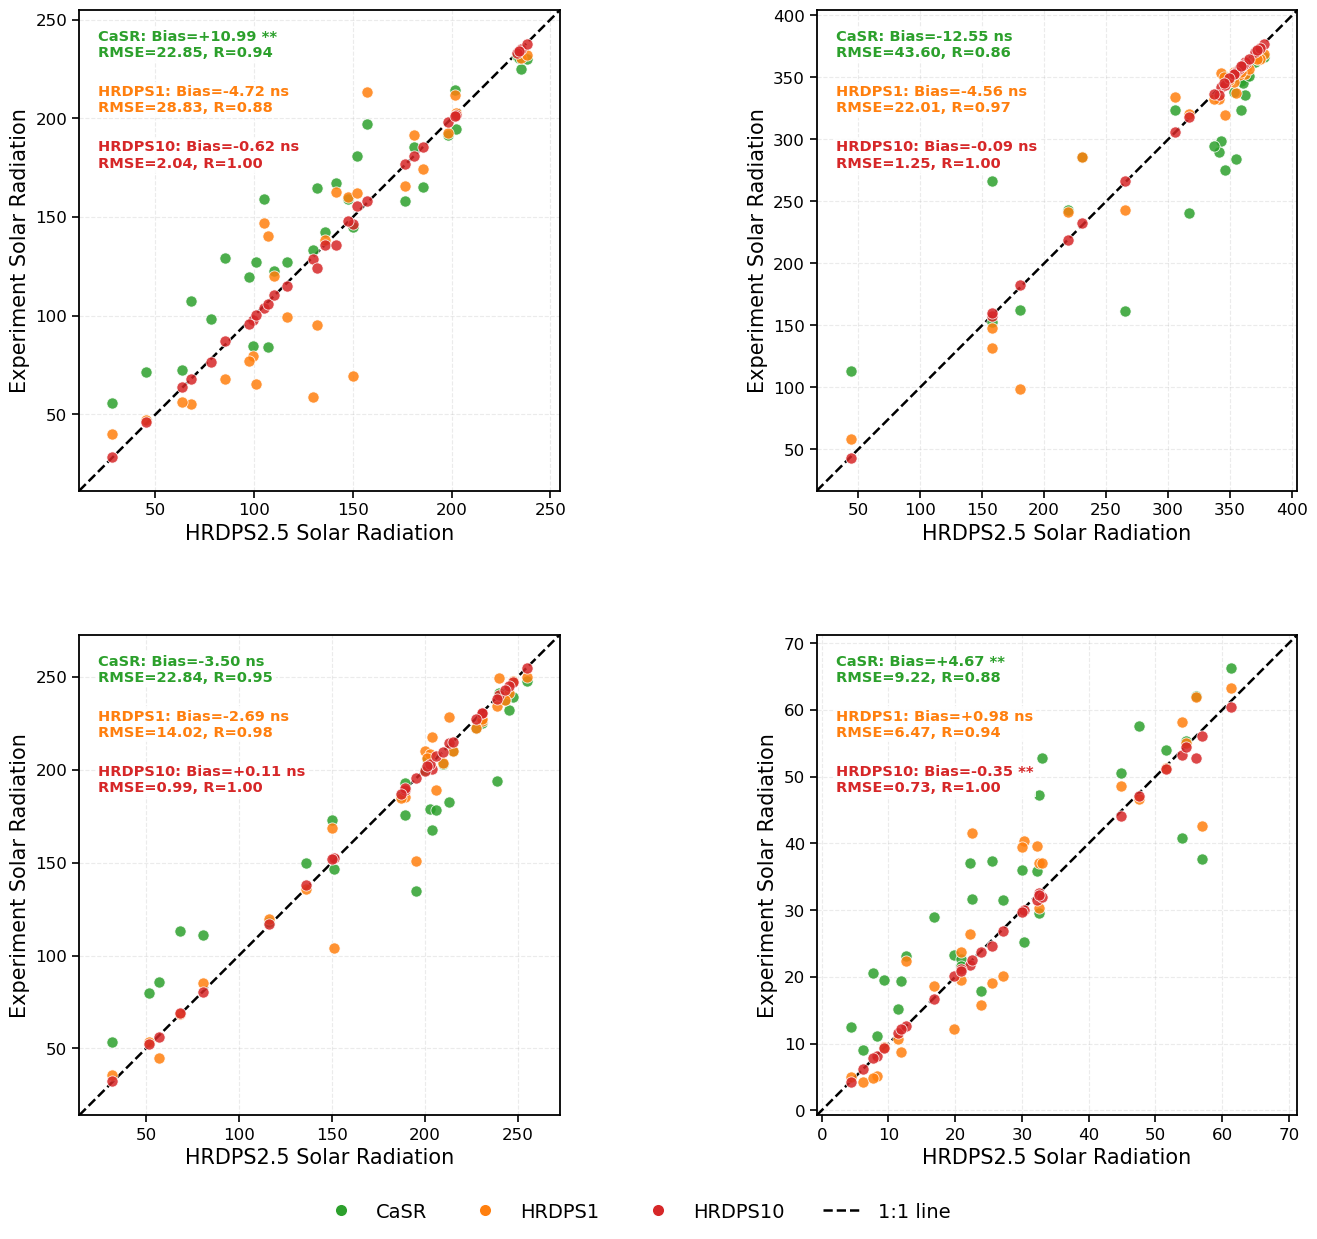

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import ttest_rel, pearsonr



# Settings
REFERENCE = "HRDPS25"
MODELS = ["CaSR", "HRDPS1", "HRDPS10"]
MONTHS = [3, 6, 9, 12]

EXPERIMENT_COLORS = {
    "HRDPS25": "tab:blue",
    "HRDPS1": "tab:orange",
    "CaSR": "tab:green",
    "HRDPS10": "tab:red",
}

# Read CSV
df = pd.read_csv(path_csv)
df.columns = df.columns.str.strip()
df["time"] = pd.to_datetime(df["time"])

columns = [REFERENCE] + MODELS
df[columns] = df[columns].apply(
    pd.to_numeric, errors="coerce"
)

# Daily mean solar radiation
daily = (
    df.set_index("time")[columns]
    .resample("1D")
    .mean()
)

# Figure settings
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 13,
    "axes.linewidth": 1.3,
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 13),
    facecolor="white"
)

axes = axes.flatten()

stats_results = []

# Scatter plots
for ax, month in zip(axes, MONTHS):

    month_data = daily[
        (daily.index.year == 2023) &
        (daily.index.month == month)
    ]

    all_values = []

    for idx, model in enumerate(MODELS):

        paired = month_data[
            [REFERENCE, model]
        ].dropna()

        x = paired[REFERENCE].values
        y = paired[model].values

        n = len(x)

        if n == 0:
            continue

        # Scatter
        ax.scatter(
            x, y,
            s=65,
            alpha=0.85,
            color=EXPERIMENT_COLORS[model],
            edgecolors="white",
            linewidths=0.6,
            zorder=3,
        )

        all_values.extend(x)
        all_values.extend(y)

        # Statistics
        bias = np.mean(y - x)
        rmse = np.sqrt(np.mean((y - x) ** 2))

        if n >= 2:
            _, p_value = ttest_rel(y, x)
        else:
            p_value = np.nan

        if (
            n >= 2
            and np.std(x) > 0
            and np.std(y) > 0
        ):
            r, _ = pearsonr(x, y)
        else:
            r = np.nan

        if p_value < 0.001:
            sig = "***"
        elif p_value < 0.01:
            sig = "**"
        elif p_value < 0.05:
            sig = "*"
        else:
            sig = "ns"

        stats_results.append({
            "Month": month,
            "Experiment": model,
            "Bias": bias,
            "RMSE": rmse,
            "R": r,
            "p_value": p_value,
            "Significance": sig,
            "N_pairs": n,
        })

        # Statistics annotation
        stats_text = (
            f"{model}: "
            f"Bias={bias:+.2f} {sig}\n"
            f"RMSE={rmse:.2f}, R={r:.2f}"
        )

        ax.text(
            0.04,
            0.96 - idx * 0.115,
            stats_text,
            transform=ax.transAxes,
            fontsize=10.5,
            fontweight="semibold",
            color=EXPERIMENT_COLORS[model],
            va="top",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.85,
                pad=2,
            ),
            zorder=10,
        )

    # 1:1 reference line
    if all_values:

        vmin = np.min(all_values)
        vmax = np.max(all_values)

        margin = 0.08 * (vmax - vmin)

        if margin == 0:
            margin = max(abs(vmax) * 0.05, 0.01)

        lims = [vmin - margin, vmax + margin]

        ax.plot(
            lims, lims,
            color="black",
            linestyle="--",
            linewidth=1.8,
            zorder=2,
        )

        ax.set_xlim(lims)
        ax.set_ylim(lims)

    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("HRDPS2.5 Solar Radiation")
    ax.set_ylabel("Experiment Solar Radiation")

    ax.tick_params(
        axis="both",
        width=1.2,
        length=5,
    )

    ax.grid(
        alpha=0.25,
        linestyle="--",
        linewidth=0.8,
    )

# Shared legend
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=9,
        markerfacecolor=EXPERIMENT_COLORS[model],
        markeredgecolor="white",
        label=model,
    )
    for model in MODELS
]

legend_handles.append(
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1.8,
        label="1:1 line",
    )
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=4,
    frameon=False,
    fontsize=14,
)

plt.subplots_adjust(
    left=0.10,
    right=0.97,
    top=0.97,
    bottom=0.12,
    hspace=0.30,
    wspace=0.30,
)

# Print statistics
stats_df = pd.DataFrame(stats_results)

print("\nDAILY MEAN SOLAR RADIATION STATISTICS")
print("Reference: HRDPS2.5")
print("Bias = Experiment - HRDPS2.5")
print("Bias and RMSE units: W/m²\n")

print(
    stats_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

plt.show()

